# 3.03 — Random Forest: ajuste, diagnóstico y evaluación

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Autor:** Erik Román Cortez
**Modelo asignado:** `RandomForestRegressor` (contrato de modelado, notebook 3.01, sección 7.7)
**Rama:** `feat/model-random-forest`

> **Problema de negocio:** pronosticar los viajes iniciados por estación y por hora del día siguiente ($d+1$), con información disponible antes de las 22:00 del día $d$, para apoyar la planeación del rebalanceo de bicicletas.

Este notebook **no redefine** el target, las features, los splits, el baseline ni las métricas: todo viene del contrato 3.01 a través de `mibici/`. Aquí se documenta cómo se ajustó el Random Forest, por qué el primer grid no superó al baseline, cómo se diagnosticó y corrigió, y cómo se comporta la configuración final.

## 1. Objetivo

1. Justificar el uso de `RandomForestRegressor` para este problema.
2. Ajustar sus hiperparámetros en *validation* (jun–jul 2026) con un diseño acotado y justificado.
3. Diagnosticar el resultado cuando no supera al baseline y corregir la causa.
4. Evaluar la configuración final en *validation* y en las dos ventanas de estabilidad (junio y julio de 2026).
5. Documentar hallazgos, limitaciones y recomendaciones para la integración.

**Regla del contrato (7.6):** un modelo es candidato si supera al baseline en WAPE en *validation* **y** en las dos ventanas. El *test* no se usa en este notebook.

## 2. Por qué Random Forest

| Característica del problema | Cómo la atiende Random Forest |
|---|---|
| Interacciones (hora × día × antigüedad de la estación) | Cada árbol divide los datos por combinaciones de variables sin que haya que programarlas |
| Relaciones no lineales con la historia (`avg_4_weeks`, `t_168`) | Los árboles aproximan cualquier forma por tramos |
| Target de conteo, ≥ 0 | El promedio de las hojas nunca es negativo |
| ~10.8 M filas de entrenamiento | `max_samples` limita la muestra *bootstrap* de cada árbol: controla costo y memoria sin submuestrear el *train* |
| Comparación con PoissonRegressor (lineal) y HistGradientBoosting (boosting) | Es el representante de *bagging*: árboles independientes promediados, menos sensible al sobreajuste que un solo árbol |

**Riesgos conocidos de antemano:** no extrapola fuera del rango visto en *train*; cada hoja predice la **media** de sus filas, y el WAPE —la métrica principal— premia la **mediana** (sección 6); es más costoso que los otros dos modelos.

## 3. Datos, contrato y cómputo

- **Datos:** `processed_v1` + features de historia, con `load_modeling_table()` (`mibici.modeling.train`).
- **Features (7):** `hour`, `day_of_week`, `is_weekend`, `month`, `station_age_days`, `avg_4_weeks`, `t_168`. Los árboles las usan sin codificar (`preprocessing = None`).
- **Splits:** *train* 2022-01-01 → 2026-05-31; *validation* 2026-06-01 → 2026-07-31; ventanas junio y julio de 2026.
- **Métricas:** WAPE (principal) y MAE, por segmento; predicciones recortadas a 0 por el pipeline común.
- **Semilla:** `random_state = 0` (`mibici.config.RANDOM_STATE`).

**Dimensionamiento previo (prueba de tamaño, no experimento).** Antes de ajustar se midió el costo en la máquina del autor (12 núcleos, 11.7 GB de RAM en WSL) con el tamaño completo de *train*:

| Configuración (100 árboles) | Tiempo | Pico de RAM |
|---|---|---|
| `max_samples` 0.05, `max_depth` 12 | 1.3 min | 3.7 GB |
| `max_samples` 0.10, `max_depth` 18 | 2.9 min | 3.9 GB |
| `criterion="poisson"` | igual que `squared_error` | igual |

Conclusión: no fue necesario submuestrear *train*. Durante el primer grid la laptop se apagó por temperatura con los 12 núcleos al 100 % (evento Kernel-Power 41 de Windows); desde el segundo grid se usa `n_jobs=6`, que **no cambia el resultado** (misma semilla, mismos árboles), solo el tiempo y el calor.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

from mibici.config import (
    FEATURES,
    FIGURES_DIR,
    MLFLOW_TRACKING_URI,
    MODELING_EXPERIMENT_NAME,
    RANDOM_STATE,
    REPORTS_DIR,
    TARGET,
)
from mibici.modeling.metrics import evaluate, wape
from mibici.modeling.models import MODELS, make_model
from mibici.modeling.pipeline import build_pipeline
from mibici.modeling.splits import train_eval_masks
from mibici.modeling.train import load_modeling_table

PREFIX = "3.03-erc"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RF_COLOR, BASE_COLOR = "#2a78d6", "#9a9893"


def save(fig, name):
    """Save a figure to reports/figures with this notebook's prefix."""
    path = FIGURES_DIR / f"{PREFIX}-{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{path.name}")

2026-11-07 12:57:37.809 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/user/mlops/MiBici


/home/user/miniforge3/envs/mibici/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Corridas registradas en MLflow

Todas las corridas se hicieron con `make train MODEL=random_forest`, una por combinación del grid, cada una con el baseline evaluado en las mismas filas. Cada etapa del ajuste quedó en un commit distinto, así que el commit identifica a qué grid pertenece cada corrida:

| Commit | Contenido del bloque `random_forest` | Corridas |
|---|---|---|
| `80ec65b` | Grid v1: `max_depth` × `max_samples` × `criterion`, sin transformación | 5 de 8 en *validation* (la 6.ª se interrumpió por el apagado) |
| `e9c1b40` | Grid v2: target `log1p`, `max_depth` × `max_features` × `min_samples_leaf` | 8 en *validation* (dos veces) y 8 en cada ventana |
| `53c68b6` | Configuración final (grid vacío) | 1 en *validation* y 1 en cada ventana |

Como el MLflow de cada integrante es local, la celda siguiente exporta las corridas a `reports/3.03-erc-mlflow-runs.csv` (archivo pequeño, versionado) cuando el servidor está disponible; si no lo está, usa ese CSV. Así el notebook se puede reproducir en cualquier máquina.

In [2]:
RUNS_CSV = REPORTS_DIR / f"{PREFIX}-mlflow-runs.csv"
GRIDS = {"80ec65b": "v1", "e9c1b40": "v2_log1p", "53c68b6": "final"}
HYPERPARAMETERS = ["max_depth", "max_samples", "criterion", "max_features", "min_samples_leaf"]
METRICS = ["all_wape", "all_mae", "established_stations_wape", "new_station_cohort_wape"]


def tidy_runs(runs: pd.DataFrame) -> pd.DataFrame:
    """One row per MLflow run with grid, mode, hyperparameters and model/baseline metrics."""
    out = pd.DataFrame(
        {
            "run": runs["tags.mlflow.runName"],
            "grid": runs["tags.git_commit"].str[:7].map(GRIDS),
            "mode": runs["params.mode"],
            "start_time": pd.to_datetime(runs["start_time"]),
        }
    )
    for name in HYPERPARAMETERS:
        # v1 logs model__regressor__<name>; with TransformedTargetRegressor (v2 and final)
        # the forest is one level deeper: model__regressor__regressor__<name>
        nested = runs.get(f"params.model__regressor__regressor__{name}")
        flat = runs.get(f"params.model__regressor__{name}")
        out[name] = nested.fillna(flat) if nested is not None else flat
    for metric in METRICS:
        out[metric] = runs[f"metrics.{metric}"]
        out[f"baseline_{metric}"] = runs[f"metrics.baseline_{metric}"]
    out["fit_seconds"] = runs["metrics.fit_seconds"]
    return out.dropna(subset=["grid"]).sort_values("start_time").reset_index(drop=True)


try:
    import mlflow

    from mibici.tracking import check_tracking_server

    check_tracking_server()
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    raw = mlflow.search_runs(
        experiment_names=[MODELING_EXPERIMENT_NAME], filter_string="params.model = 'random_forest'"
    )
    tidy_runs(raw).to_csv(RUNS_CSV, index=False)
    print(f"Updated from MLflow: {RUNS_CSV.name}")
except Exception as error:  # no server or no runs on this machine
    print(f"MLflow not available ({type(error).__name__}); using {RUNS_CSV.name}")

runs = pd.read_csv(RUNS_CSV, parse_dates=["start_time"])
runs.groupby(["grid", "mode"]).size().rename("runs").to_frame()

Updated from MLflow: 3.03-erc-mlflow-runs.csv


runs
grid     mode             
final    validation      1
         window_july     1
         window_june     1
v1       validation      5
v2_log1p validation     16
         window_july     8
         window_june     8

## 5. Grid v1: Random Forest sin transformación

**Diseño:** factorial 2 × 2 × 2 sobre los hiperparámetros que controlan complejidad y costo, con `n_estimators = 100` y `min_samples_leaf = 50` fijos.

| Hiperparámetro | Valores | Pregunta |
|---|---|---|
| `max_depth` | 12, 18 | ¿Más complejidad ayuda o sobreajusta? |
| `max_samples` | 0.05, 0.10 | ¿Más datos por árbol mejoran la precisión? |
| `criterion` | `squared_error`, `poisson` | ¿El criterio para conteos ayuda con un target con 42.8 % de ceros? |

In [3]:
cols = ["run", "max_depth", "max_samples", "criterion", "all_wape", "baseline_all_wape",
        "established_stations_wape", "new_station_cohort_wape", "fit_seconds"]
v1 = runs[(runs["grid"] == "v1") & (runs["mode"] == "validation")]
v1[cols].round(4)

,run,max_depth,max_samples,criterion,all_wape,baseline_all_wape,established_stations_wape,new_station_cohort_wape,fit_seconds
0,random_forest-validation-01,12,0.05,squared_error,0.7180,0.6964,0.6952,1.2204,90.3998
1,random_forest-validation-02,12,0.10,squared_error,0.7173,0.6964,0.6944,1.2230,190.1751
2,random_forest-validation-03,18,0.05,squared_error,0.7175,0.6964,0.6944,1.2295,93.6174
3,random_forest-validation-04,18,0.10,squared_error,0.7170,0.6964,0.6934,1.2396,198.4950
4,random_forest-validation-05,12,0.05,poisson,0.7180,0.6964,0.6953,1.2205,84.0779


**Interpretación**

- **Ninguna configuración supera al baseline:** WAPE 0.717–0.718 frente a 0.696, en todos los segmentos (consolidadas ≈ 0.694 frente a 0.678; cohorte nueva ≈ 1.22 frente a 1.10).
- **Los hiperparámetros no mueven el resultado:** duplicar los datos por árbol, hacer los árboles seis veces más grandes o cambiar a `poisson` deja el WAPE en el mismo valor.
- Si más capacidad no ayuda, el problema **no es de complejidad sino de sesgo**: el modelo se equivoca de forma sistemática en una dirección. Seguir moviendo los mismos hiperparámetros no aportaría información; hacía falta un diagnóstico (sección 6).

## 6. Diagnóstico: ¿en qué dirección se equivoca?

Se reentrena la configuración más ligera del grid v1 (`max_depth` 12, `max_samples` 0.05, `squared_error`) y se compara con lo observado en *validation*. Es el mismo pipeline común (`build_pipeline`), solo con otro estimador; no se registra en MLflow.

In [4]:
data = load_modeling_table()
train, evaluated = train_eval_masks(data, "validation")
eval_rows = data[evaluated]
y_eval = eval_rows[TARGET].to_numpy(dtype=float)
baseline_pred = eval_rows["avg_4_weeks"].to_numpy()  # the baseline is exactly this feature

rf_v1 = build_pipeline(
    RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_depth=12, max_samples=0.05,
                          random_state=RANDOM_STATE, n_jobs=6)
)
rf_v1.fit(data[train], data.loc[train, TARGET])
v1_pred = rf_v1.predict(eval_rows)

segment = np.where(eval_rows["is_new_station_cohort"], "new_station_cohort", "established")
month = eval_rows["hour_start"].dt.month.to_numpy()
diagnosis = (
    pd.DataFrame({"segment": segment, "month": month, "observed": y_eval,
                  "rf_v1": v1_pred, "baseline": baseline_pred})
    .groupby(["segment", "month"]).mean().round(3)
)
print(f"Rows over-predicted → RF v1: {(v1_pred > y_eval).mean():.1%} | "
      f"baseline: {(baseline_pred > y_eval).mean():.1%}")
diagnosis

Rows over-predicted → RF v1: 66.1% | baseline: 45.8%


observed  rf_v1  baseline
segment            month                           
established        6         1.483  1.506     1.424
                   7         1.546  1.620     1.555
new_station_cohort 6         0.577  0.606     0.535
                   7         0.449  0.536     0.442

Figure saved: reports/figures/3.03-erc-v1-diagnosis.png


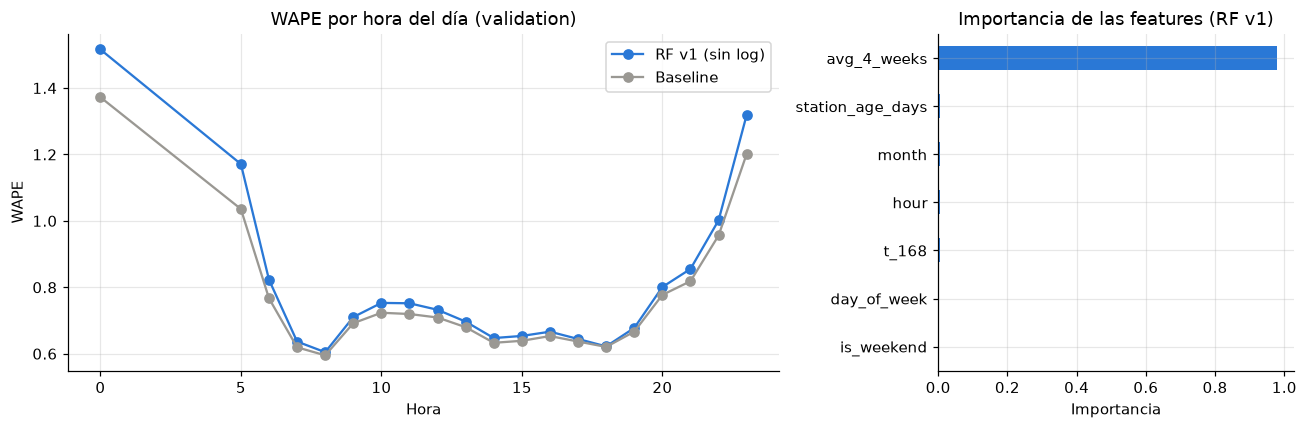

,importance
avg_4_weeks,0.978
station_age_days,0.006
month,0.006
hour,0.005
t_168,0.004
day_of_week,0.002
is_weekend,0.000


In [5]:
importance = pd.Series(rf_v1.named_steps["model"].regressor_.feature_importances_, index=FEATURES)
hour = eval_rows["hour"].to_numpy()
by_hour = pd.DataFrame(
    {h: {"RF v1": wape(y_eval[hour == h], v1_pred[hour == h]),
         "Baseline": wape(y_eval[hour == h], baseline_pred[hour == h])} for h in np.unique(hour)}
).T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(by_hour.index, by_hour["RF v1"], marker="o", color=RF_COLOR, label="RF v1 (sin log)")
ax1.plot(by_hour.index, by_hour["Baseline"], marker="o", color=BASE_COLOR, label="Baseline")
ax1.set(title="WAPE por hora del día (validation)", xlabel="Hora", ylabel="WAPE")
ax1.legend()
importance.sort_values().plot.barh(ax=ax2, color=RF_COLOR)
ax2.set(title="Importancia de las features (RF v1)", xlabel="Importancia")
fig.tight_layout()
save(fig, "v1-diagnosis")
plt.show()
importance.sort_values(ascending=False).round(3).to_frame("importance")

**Interpretación**

- **El RF v1 sobrestima:** predice de más en ≈ 2 de cada 3 filas (el óptimo para un error absoluto es ≈ 50 %) y su promedio queda por encima de lo observado en todos los segmentos; en la cohorte nueva de julio, ≈ +19 %.
- **Pierde en todas las horas**, y más en las de poca demanda (00:00, 05:00, 23:00), donde el conteo es más sesgado: casi siempre 0 o 1 salida, con picos raros.
- **`avg_4_weeks` concentra ≈ 98 % de la importancia:** el RF funciona como una versión suavizada del baseline.

**Causa: media frente a mediana.** Una hoja de un árbol con `squared_error` (o `poisson`) predice el **promedio** de sus filas; el valor que minimiza el error **absoluto** —el que mide el WAPE— es la **mediana**. Con conteos sesgados, los picos jalan el promedio hacia arriba. La celda siguiente lo muestra con una hoja de ejemplo.

In [6]:
leaf = np.array([0, 0, 1, 1, 8])  # five departures counts that fall in the same leaf
for name, value in {"mean": leaf.mean(), "median": np.median(leaf),
                    "exp(mean(log1p)) - 1": np.expm1(np.log1p(leaf).mean())}.items():
    print(f"{name:>22}: prediction {value:.2f} → total absolute error {np.abs(leaf - value).sum():.2f}")

                  mean: prediction 2.00 → total absolute error 12.00
                median: prediction 1.00 → total absolute error 9.00
  exp(mean(log1p)) - 1: prediction 1.05 → total absolute error 9.14


El promedio (2.0) produce más error absoluto que la mediana (1.0). Entrenar sobre $\log(1+y)$ y regresar con $e^{x}-1$ produce una predicción intermedia (≈ 1.0 en el ejemplo), mucho más cercana a la mediana, **sin cambiar el target ni la métrica**: el modelo sigue prediciendo salidas.

La alternativa directa, `criterion="absolute_error"`, optimiza la mediana pero es demasiado lenta con 10.8 M filas; la transformación `log1p` cuesta lo mismo que `squared_error`.

## 7. Grid v2: Random Forest sobre `log1p(departures)`

El estimador se envuelve en `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`. El grid v1 mostró que `max_samples` y `criterion` no influyen, así que se fijan (`max_samples` 0.05, `squared_error`) y el nuevo factorial prueba hiperparámetros que sí podían cambiar el resultado:

| Hiperparámetro | Valores | Hipótesis |
|---|---|---|
| `max_depth` | 12, 18 | ¿Con el log, más profundidad ahora sí ayuda? |
| `max_features` | 1.0, 0.5 | Con 0.5, algunas divisiones deben usar hora, día o antigüedad en lugar de `avg_4_weeks` |
| `min_samples_leaf` | 50, 200 | Suavizado de las hojas |

El grid v2 se ejecutó dos veces en *validation* (por un error al guardar el bloque final); se usa la primera ejecución y la segunda sirve como prueba de reproducibilidad.

In [7]:
v2_all = runs[(runs["grid"] == "v2_log1p") & (runs["mode"] == "validation")].copy()
v2_all["execution"] = v2_all.groupby("run").cumcount() + 1  # 1 = first, 2 = repeated grid
v2 = v2_all[v2_all["execution"] == 1]

# Reproducibility: the same configuration on the same commit must give the same metrics
pair = v2_all.pivot(index="run", columns="execution", values="all_wape")
if pair.shape[1] == 2:
    print(f"Max |WAPE run 1 - run 2| across the 8 configurations: {(pair[1] - pair[2]).abs().max():.6f}")

cols = ["run", "max_depth", "max_features", "min_samples_leaf", "all_wape", "all_mae",
        "established_stations_wape", "new_station_cohort_wape", "fit_seconds"]
v2[cols].sort_values(["all_wape", "fit_seconds"]).round(4)

Max |WAPE run 1 - run 2| across the 8 configurations: 0.000000


,run,max_depth,max_features,min_samples_leaf,all_wape,all_mae,established_stations_wape,new_station_cohort_wape,fit_seconds
11,random_forest-validation-07,18,0.5,50,0.6898,0.9580,0.6709,1.1094,43.0406
10,random_forest-validation-06,18,1.0,200,0.6900,0.9582,0.6709,1.1123,73.5436
12,random_forest-validation-08,18,0.5,200,0.6900,0.9582,0.6709,1.1127,41.4877
7,random_forest-validation-03,12,0.5,50,0.6901,0.9583,0.6711,1.1107,41.8998
8,random_forest-validation-04,12,0.5,200,0.6903,0.9586,0.6712,1.1124,43.0944
6,random_forest-validation-02,12,1.0,200,0.6905,0.9588,0.6714,1.1119,70.7575
5,random_forest-validation-01,12,1.0,50,0.6910,0.9595,0.6720,1.1111,78.9838
9,random_forest-validation-05,18,1.0,50,0.6911,0.9597,0.6718,1.1175,77.0161


In [8]:
# Main effect of each factor: mean WAPE at each level, over the other two factors
effects = pd.concat(
    {factor: v2.groupby(factor)["all_wape"].mean() for factor in
     ["max_depth", "max_features", "min_samples_leaf"]}
).rename("mean WAPE").to_frame()
effects["mean WAPE"] = effects["mean WAPE"].round(5)
effects

mean WAPE
max_depth        12.0     0.69045
                 18.0     0.69024
max_features     0.5      0.69005
                 1.0      0.69063
min_samples_leaf 50.0     0.69049
                 200.0    0.69019

**Interpretación**

- **Las 8 configuraciones superan al baseline en *validation*:** WAPE 0.690–0.691 frente a 0.696 y MAE ≈ 0.958 frente a 0.967. La mejora frente al grid v1 (≈ 0.027 de WAPE) viene de la **transformación**, no de los hiperparámetros.
- **Efectos principales < 0.001** en los tres factores: con el sesgo corregido, la configuración casi no importa. `max_features = 0.5` es ligeramente mejor y **cuesta la mitad** (≈ 42 s frente a ≈ 75 s).
- **Reproducibilidad:** las dos ejecuciones del grid dan exactamente el mismo WAPE en las 8 configuraciones (solo cambia `fit_seconds`).
- **Mejora en las consolidadas** (≈ 0.671 frente a 0.678), **no en la cohorte nueva** (≈ 1.11 frente a 1.104).

### 7.1 Selección

**Regla, fijada antes de ver las ventanas:** menor WAPE en *validation*; si dos configuraciones difieren menos de 0.001, se elige la más simple y barata (parsimonia).

- Mejor estricta: corrida **07** (`max_depth` 18, `max_features` 0.5, `min_samples_leaf` 50), WAPE 0.6898.
- **Elegida: corrida 03** (`max_depth` **12**, `max_features` 0.5, `min_samples_leaf` 50), WAPE 0.6901: a 0.0003 de la mejor, con árboles menos profundos y el mismo tiempo.

Las ventanas **no** se usan para elegir: convertirlas en otro set de ajuste les quitaría su valor como prueba de estabilidad.

## 8. Configuración final

Bloque `random_forest` de `mibici/modeling/models.py` (commit `53c68b6`), con `param_grid` vacío para que `make train` la reproduzca:

In [9]:
MODELS["random_forest"]["estimator"]

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",RandomForestR...andom_state=0)
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See

In [10]:
rf_final = make_model("random_forest").fit(data[train], data.loc[train, TARGET])
final_pred = rf_final.predict(eval_rows)

scores = pd.concat(
    {"RF final": evaluate(eval_rows, final_pred)[["wape", "mae"]],
     "Baseline": evaluate(eval_rows, baseline_pred)[["wape", "mae"]]}, axis=1
).round(4)
print(f"Rows over-predicted → RF final: {(final_pred > y_eval).mean():.1%} | "
      f"baseline: {(baseline_pred > y_eval).mean():.1%}")
print(f"Total departures (validation) → observed {y_eval.sum():,.0f} | RF final {final_pred.sum():,.0f} "
      f"({final_pred.sum() / y_eval.sum() - 1:+.1%}) | baseline {baseline_pred.sum():,.0f} "
      f"({baseline_pred.sum() / y_eval.sum() - 1:+.1%})")
scores

Rows over-predicted → RF final: 60.8% | baseline: 45.8%
Total departures (validation) → observed 710,943 | RF final 588,871 (-17.2%) | baseline 699,038 (-1.7%)


RF final         Baseline        
                         wape     mae     wape     mae
segment                                               
all                    0.6901  0.9583   0.6964  0.9670
established_stations   0.6711  1.0167   0.6779  1.0271
new_station_cohort     1.1107  0.5422   1.1037  0.5388

Figure saved: reports/figures/3.03-erc-final-wape-by-hour.png


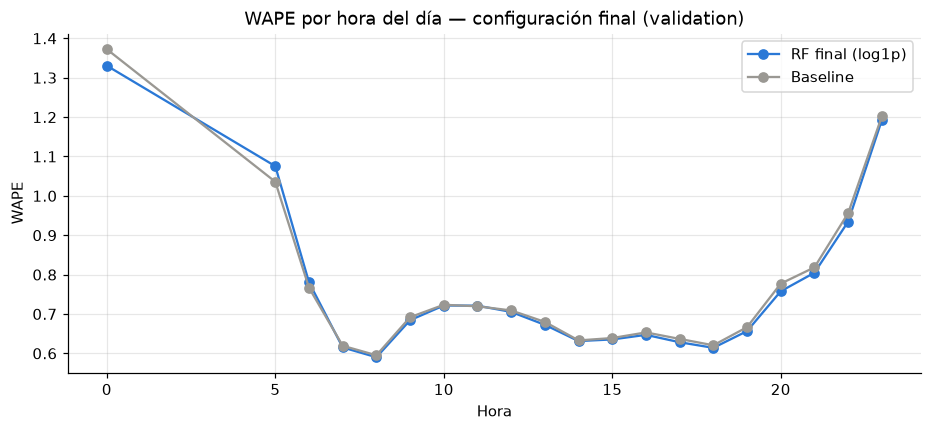

RF better
True     17
False     3
Name: count, dtype: int64

In [11]:
by_hour_final = pd.DataFrame(
    {h: {"RF final": wape(y_eval[hour == h], final_pred[hour == h]),
         "Baseline": wape(y_eval[hour == h], baseline_pred[hour == h])} for h in np.unique(hour)}
).T
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_hour_final.index, by_hour_final["RF final"], marker="o", color=RF_COLOR, label="RF final (log1p)")
ax.plot(by_hour_final.index, by_hour_final["Baseline"], marker="o", color=BASE_COLOR, label="Baseline")
ax.set(title="WAPE por hora del día — configuración final (validation)", xlabel="Hora", ylabel="WAPE")
ax.legend()
save(fig, "final-wape-by-hour")
plt.show()
(by_hour_final["RF final"] < by_hour_final["Baseline"]).rename("RF better").value_counts()

**Interpretación**

- **Mejora en total y en las consolidadas:** WAPE 0.690 frente a 0.696 y MAE 0.958 frente a 0.967; en las consolidadas, 0.671 frente a 0.678. En la cohorte nueva queda prácticamente empatado (1.111 frente a 1.104).
- **Gana en 17 de las 20 horas de servicio.** La mayor mejora es a las 00:00 (≈ 1.33 frente a 1.37). Pierde en el arranque del servicio (05:00 y 06:00), donde la demanda sube rápido desde casi cero y la transformación logarítmica aplana justo ese crecimiento.
- **El 60.8 % de las filas sigue sobrestimado**, contra 45.8 % del baseline. No contradice la mejora: en las muchas horas con 0 salidas, cualquier predicción positiva cuenta como sobrestimar, mientras que en las horas de alta demanda el modelo se queda corto.
- **Subpronóstico agregado: el RF predice 588,871 salidas frente a 710,943 observadas (−17.2 %)**; el baseline, −1.7 %. Es el costo de acercarse a la mediana: mejora el error por estación-hora (lo que mide el WAPE), pero subestima el total. Para el rebalanceo, que planea flotas con totales, es la limitación más importante de este modelo (sección 11).

## 9. Estabilidad: validation y ventanas

Corridas de la configuración final desde su propio commit (`53c68b6`), con `make train MODEL=random_forest MODE=<modo>`. El baseline se evalúa en las mismas filas de cada modo.

Figure saved: reports/figures/3.03-erc-final-stability.png


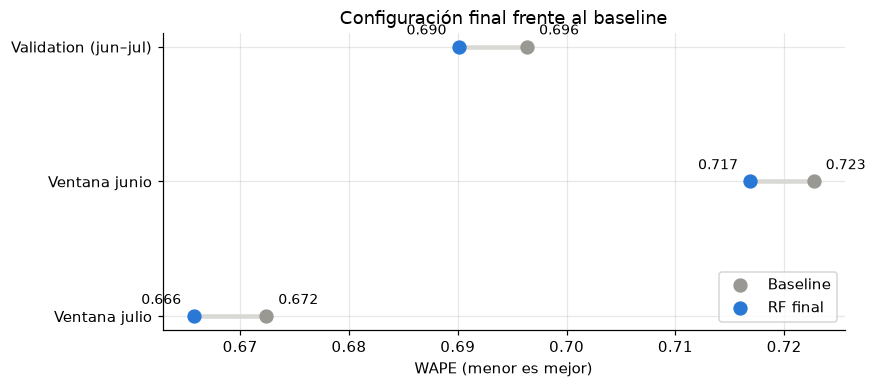

,all_wape,baseline_all_wape,all_mae,baseline_all_mae,new_station_cohort_wape,baseline_new_station_cohort_wape,wape_gain,beats_baseline
mode,,,,,,,,
validation,0.6901,0.6964,0.9583,0.9670,1.1107,1.1037,0.0063,True
window_june,0.7169,0.7227,1.0109,1.0191,1.1071,1.1506,0.0058,True
window_july,0.6657,0.6724,0.9119,0.9210,1.1050,1.0769,0.0067,True


In [12]:
final_runs = runs[runs["grid"] == "final"].drop_duplicates("mode", keep="last").set_index("mode")
stability = final_runs.loc[["validation", "window_june", "window_july"],
                           ["all_wape", "baseline_all_wape", "all_mae", "baseline_all_mae",
                            "new_station_cohort_wape", "baseline_new_station_cohort_wape"]]
stability["wape_gain"] = stability["baseline_all_wape"] - stability["all_wape"]
stability["beats_baseline"] = stability["all_wape"] < stability["baseline_all_wape"]

# Dot plot: the WAPE axis does not need to start at 0, so small gaps are shown honestly
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(stability))[::-1]
ax.hlines(y, stability["all_wape"], stability["baseline_all_wape"], color="#d9d8d4", lw=3)
ax.scatter(stability["baseline_all_wape"], y, color=BASE_COLOR, s=70, label="Baseline", zorder=3)
ax.scatter(stability["all_wape"], y, color=RF_COLOR, s=70, label="RF final", zorder=3)
for yi, (rf, base) in zip(y, zip(stability["all_wape"], stability["baseline_all_wape"])):
    ax.annotate(f"{rf:.3f}", (rf, yi), xytext=(-8, 8), textcoords="offset points", ha="right", fontsize=9)
    ax.annotate(f"{base:.3f}", (base, yi), xytext=(8, 8), textcoords="offset points", fontsize=9)
ax.set_yticks(y, ["Validation (jun–jul)", "Ventana junio", "Ventana julio"])
ax.set(xlabel="WAPE (menor es mejor)", title="Configuración final frente al baseline")
ax.legend(loc="lower right")
save(fig, "final-stability")
plt.show()
stability.round(4)

**Interpretación**

- **El Random Forest es candidato según el contrato (7.6):** supera al baseline en *validation* (0.690 frente a 0.696), en junio (0.717 frente a 0.723) y en julio (0.666 frente a 0.672).
- **La mejora es estable y pequeña:** ≈ 0.006 de WAPE en los tres periodos (≈ 0.9 % de error relativo menos). Las 8 configuraciones del grid v2 ganan también en ambas ventanas (0.716–0.718 en junio; 0.666–0.667 en julio), así que la mejora no depende de la configuración elegida.
- **Cohorte nueva, resultado mixto:** el RF gana en junio (1.107 frente a 1.151, el mes en que abren la mayoría de las estaciones), pero pierde en julio (1.105 frente a 1.077) y en *validation* completo (1.111 frente a 1.104). No hay una mejora consistente en el *cold start*.
- **Reproducibilidad:** la configuración final, ejecutada desde su commit, da el mismo WAPE que la corrida 03 del grid (0.690; 0.717; 0.666): misma configuración, mismo resultado, desde otro commit.

## 10. Hallazgos

1. Sin transformación, el Random Forest **no supera al baseline** con ningún hiperparámetro de tamaño o criterio (WAPE 0.717–0.718 frente a 0.696).
2. **Causa diagnosticada:** cada hoja predice la media y el WAPE premia la mediana; con conteos sesgados, el modelo sobrestima en ≈ 2 de cada 3 filas.
3. **Corrección:** entrenar sobre `log1p(departures)` con `TransformedTargetRegressor` reduce el WAPE ≈ 0.027 y lo pone por debajo del baseline, sin cambiar target, features, métricas ni pipeline.
4. **Configuración final** (`max_depth` 12, `max_features` 0.5, `min_samples_leaf` 50, `max_samples` 0.05, 100 árboles): **candidata**, gana en *validation* y en las dos ventanas por ≈ 0.006.
5. **Costo de la corrección:** el RF final subestima el total de salidas en *validation* (−17.2 %, frente a −1.7 % del baseline).
6. Los hiperparámetros apenas importan (efectos < 0.001): con estas 7 features, el modelo depende casi por completo de `avg_4_weeks`.

## 11. Limitaciones y riesgos

- **Mejora pequeña:** ≈ 0.9 % menos error relativo que una regla de cuatro semanas. Puede no justificar operativamente el costo de un modelo más complejo; se decide al comparar con Poisson y HGB.
- **Estaciones nuevas:** el resultado en la cohorte 2026 es mixto (gana en junio, pierde en julio y en *validation*): sin historia propia, las features no tienen de dónde aprender (*cold start*).
- **Subpronóstico agregado:** `log1p` acerca las predicciones a la mediana, pero el total predicho queda **17.2 % por debajo** de las salidas reales (sección 8). Para el rebalanceo, que planea con totales, es un sesgo a vigilar; una calibración del total (por ejemplo, un factor estimado solo con *train*) es una mejora posible para la Fase 3.
- **Media frente a mediana es un tema del equipo:** cualquier modelo con pérdida cuadrática o de Poisson tiene el mismo sesgo frente al WAPE.
- **Cómputo:** con `n_jobs=-1` la laptop se apagó por temperatura; la configuración final usa `n_jobs=6`.

## 12. Recomendaciones

- **Para la integración:** comparar los tres modelos con los mismos periodos y revisar también el **total de salidas pronosticado**, no solo el WAPE: un modelo que gana en WAPE puede subestimar la flota necesaria.
- **Para HGB y Poisson:** probar `loss="absolute_error"` o `"quantile"` (HGB) y revisar si Poisson también sobrestima.
- **Fase 3:** features que aporten información distinta de `avg_4_weeks` (ubicación de la estación, clima, festivos y vacaciones del EDA 1.02) y un tratamiento específico para estaciones nuevas; monitorear la deriva por la expansión de la red.

## 13. Roles e interacción

| Rol | Actividad en este notebook | Interacción |
|---|---|---|
| **Data Scientist** (Erik) | Selección y justificación del modelo, diseño de los grids, diagnóstico media/mediana, selección por parsimonia | Usa el contrato del integrador sin modificarlo; comparte el hallazgo con los dueños de Poisson y HGB |
| **ML Engineer** (Erik) | Bloque `random_forest` en `models.py`, corridas con `make train`, registro en MLflow, exportación de corridas a CSV | Entrega la configuración final en Git para que el integrador la reproduzca y la registre en el Model Registry |
| **SRE** (Erik) | Dimensionamiento de memoria y tiempo, diagnóstico del apagado térmico, `n_jobs=6` | Reporta al integrador el hardware disponible (pendiente 7.8 del contrato) |
| **Software Engineer** (Erik → Leonardo) | Ajuste de `test_models_use_the_common_seed` para estimadores envueltos, en un commit aparte | Cambio a una pieza compartida propuesto al integrador para revisión |

---
*Declaración de uso de IA:* Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande]. Utilizado como tutor y asistente de programación para el dimensionamiento de cómputo, el diagnóstico del sesgo, el diseño de los grids y la elaboración preliminar del código y la redacción de este notebook. Las decisiones, ejecuciones y verificación de resultados fueron realizadas y revisadas por el autor.